# Day 1 — OCR Landscape and Image Preprocessing

**Module 4: Document Understanding**

**Goal:** Compare self-hosted OCR tools (Tesseract and EasyOCR), extract raw text from a sample document, and see how deskewing, denoising, and thresholding affect OCR output.

This notebook uses a synthetic invoice generated locally, so it does not depend on an external image download.

### 1. Install dependencies

In [1]:
!apt-get -qq update
!apt-get -qq install -y tesseract-ocr
!pip -q install easyocr opencv-python-headless pillow matplotlib pandas

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


In [3]:
!pip install -q pytesseract
!apt-get -qq install -y tesseract-ocr

### 2. Imports and installation check

In [4]:
import cv2
import easyocr
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pytesseract

from PIL import Image, ImageDraw, ImageFont
from pathlib import Path

print("Tesseract:", pytesseract.get_tesseract_version())
print("OpenCV:", cv2.__version__)
print("EasyOCR imported successfully")

Tesseract: 5.3.4
OpenCV: 4.14.0
EasyOCR imported successfully


### 3. Create a sample invoice image

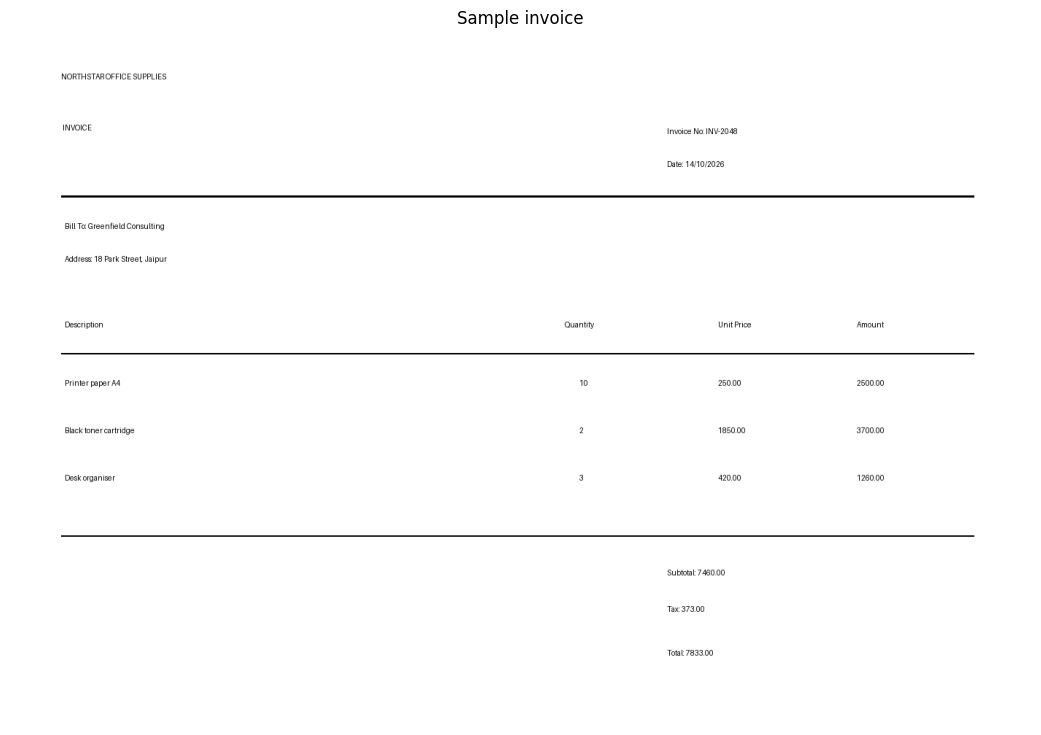

Image size: (1400, 950)


In [5]:
width, height = 1400, 950
image = Image.new("RGB", (width, height), "white")
draw = ImageDraw.Draw(image)

try:
    title_font = ImageFont.truetype("DejaVuSans-Bold.ttf", 42)
    heading_font = ImageFont.truetype("DejaVuSans-Bold.ttf", 27)
    body_font = ImageFont.truetype("DejaVuSans.ttf", 24)
except OSError:
    title_font = heading_font = body_font = ImageFont.load_default()

draw.text((70, 55), "NORTHSTAR OFFICE SUPPLIES", fill="black", font=title_font)
draw.text((72, 125), "INVOICE", fill="black", font=heading_font)
draw.text((900, 130), "Invoice No: INV-2048", fill="black", font=body_font)
draw.text((900, 175), "Date: 14/10/2026", fill="black", font=body_font)
draw.line((70, 225, 1320, 225), fill="black", width=3)
draw.text((75, 260), "Bill To: Greenfield Consulting", fill="black", font=body_font)
draw.text((75, 305), "Address: 18 Park Street, Jaipur", fill="black", font=body_font)

draw.text((75, 395), "Description", fill="black", font=heading_font)
draw.text((760, 395), "Quantity", fill="black", font=heading_font)
draw.text((970, 395), "Unit Price", fill="black", font=heading_font)
draw.text((1160, 395), "Amount", fill="black", font=heading_font)
draw.line((70, 440, 1320, 440), fill="black", width=2)

rows = [
    ("Printer paper A4", "10", "250.00", "2500.00"),
    ("Black toner cartridge", "2", "1850.00", "3700.00"),
    ("Desk organiser", "3", "420.00", "1260.00"),
]
y = 475
for desc, qty, price, amount in rows:
    draw.text((75, y), desc, fill="black", font=body_font)
    draw.text((780, y), qty, fill="black", font=body_font)
    draw.text((970, y), price, fill="black", font=body_font)
    draw.text((1160, y), amount, fill="black", font=body_font)
    y += 65

draw.line((70, 690, 1320, 690), fill="black", width=2)
draw.text((900, 735), "Subtotal: 7460.00", fill="black", font=body_font)
draw.text((900, 785), "Tax: 373.00", fill="black", font=body_font)
draw.text((900, 845), "Total: 7833.00", fill="black", font=heading_font)

plt.figure(figsize=(14, 9))
plt.imshow(image)
plt.axis("off")
plt.title("Sample invoice")
plt.show()
print("Image size:", image.size)

### 4. Run Tesseract OCR

In [6]:
tesseract_text = pytesseract.image_to_string(image, config="--psm 6")
print(tesseract_text)

NORTHSTAROFFICE SUPPLIES
INVOICE Invoice Na INV-2048,
Date: 14/10/2028
Bill Ta Greenfield Consulting
‘Address 18 Park Steet Jaipur
Description Quantity Unit Price ‘Amount
Printer paper Ad 10 2000 2500.00
Black toner cartridge 2 1850.00 3700.00
Desk organiser 3 420.00 1260.00
Subtotat 7460.00
Tax 37300
Total 783300



### 5. Run EasyOCR

In [7]:
reader = easyocr.Reader(["en"], gpu=False)
easy_results = reader.readtext(np.array(image))
easy_text = "\\n".join([item[1] for item in easy_results])

print(easy_text)
print("Detected text regions:", len(easy_results))

Progress: |██████████████████████████████████████████████████| 100.0% Complete

Progress: |██████████████████████████████████████████████████| 100.0% Complete

/usr/local/lib/python3.13/dist-packages/torch/ao/nn/quantized/dynamic/modules/rnn.py:162: UserWarning: torch.quantize_per_tensor, torch.quantize_per_channel and other quantized tensor creation functions that produce tensors with dtype torch.quint8, torch.qint8, and torch.qint32 are deprecated and will be removed in a future PyTorch release. Please see https://github.com/pytorch/pytorch/issues/184982 for more information. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/quantized/Quantizer.cpp:111.)
  w_ih = torch.quantize_per_tensor(


NORTHSTAROFFICE SUPPLIES\nINVOICE\nInvoice Na INV-2048\nDate: 14'10/2026\nBill To Greenfield Consulting\nAddress 18 Park Street Jaipur\nDescription\nQuantity\nUnit Price\nAmount\nPrinter paper A4\n250.00\n2500.00\nBlack toner cartridge\n1850.00\n3700.00\nDesk organisel\n420nn\n1280.00\nSubtotal:\n480.00\nTax 373.00\nTotal: 7833.00
Detected text regions: 23


### 6. Compare OCR outputs

In [8]:
comparison = pd.DataFrame([
    {
        "Engine": "Tesseract",
        "Text characters": len(tesseract_text),
        "Non-empty lines": len([x for x in tesseract_text.splitlines() if x.strip()])
    },
    {
        "Engine": "EasyOCR",
        "Text characters": len(easy_text),
        "Non-empty lines": len([x for x in easy_text.splitlines() if x.strip()])
    }
])
comparison

,Engine,Text characters,Non-empty lines
0,Tesseract,316,12
1,EasyOCR,332,1


### 7. Visualise EasyOCR text regions

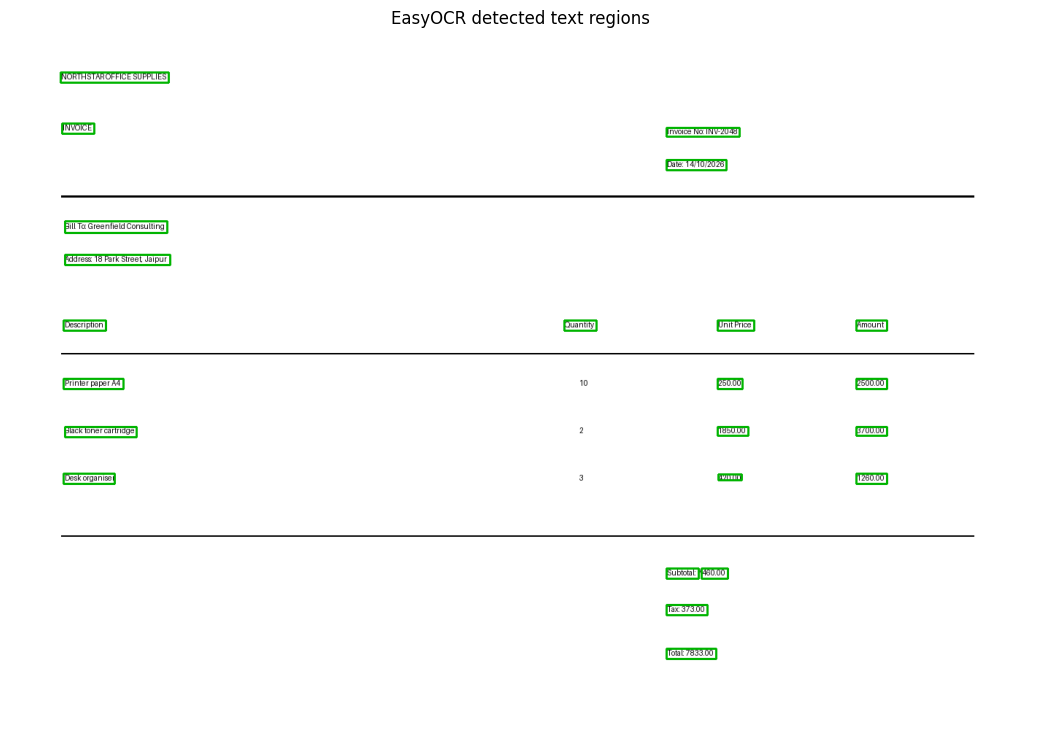

In [9]:
annotated = np.array(image).copy()
for bbox, text, confidence in easy_results:
    points = np.array(bbox, dtype=np.int32)
    cv2.polylines(annotated, [points], True, (0, 180, 0), 2)

plt.figure(figsize=(14, 9))
plt.imshow(annotated)
plt.axis("off")
plt.title("EasyOCR detected text regions")
plt.show()

### 8. Preprocessing: grayscale and denoising

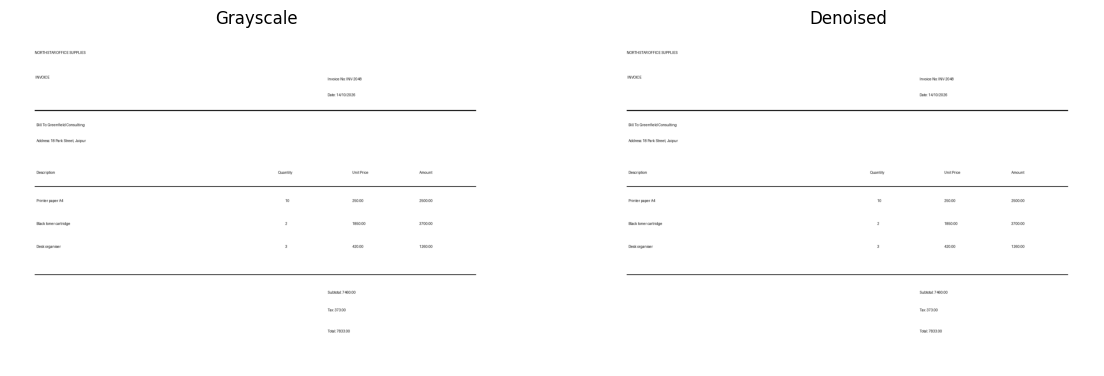

In [10]:
gray = cv2.cvtColor(np.array(image), cv2.COLOR_RGB2GRAY)
denoised = cv2.fastNlMeansDenoising(
    gray, None, h=15, templateWindowSize=7, searchWindowSize=21
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].imshow(gray, cmap="gray")
axes[0].set_title("Grayscale")
axes[0].axis("off")
axes[1].imshow(denoised, cmap="gray")
axes[1].set_title("Denoised")
axes[1].axis("off")
plt.show()

### 9. Thresholding

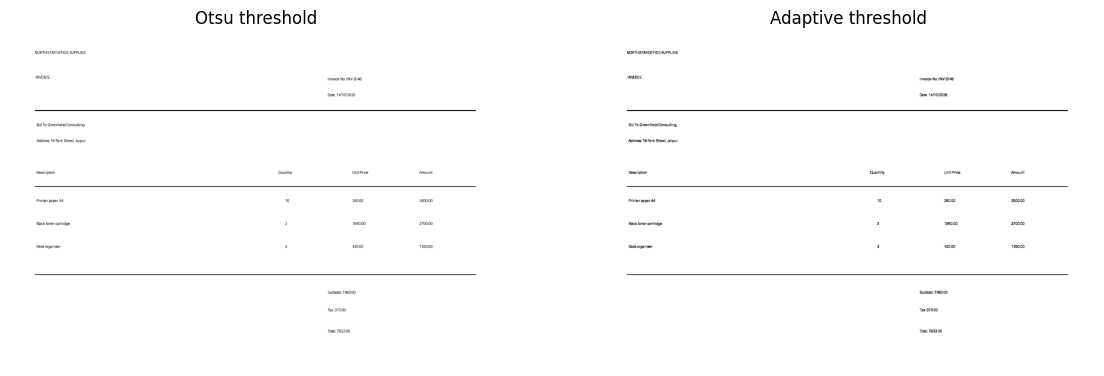

In [11]:
_, otsu = cv2.threshold(
    denoised, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
)
adaptive = cv2.adaptiveThreshold(
    denoised, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY, 31, 11
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].imshow(otsu, cmap="gray")
axes[0].set_title("Otsu threshold")
axes[0].axis("off")
axes[1].imshow(adaptive, cmap="gray")
axes[1].set_title("Adaptive threshold")
axes[1].axis("off")
plt.show()

### 10. Deskewing

Estimated correction angle: 5.48 degrees


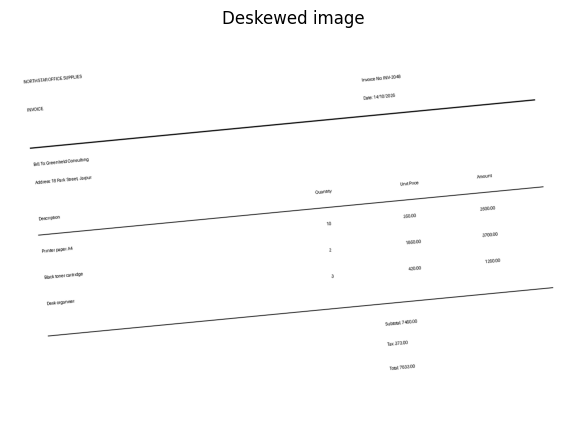

In [12]:
def deskew_image(binary_image):
    coords = np.column_stack(np.where(binary_image < 255))
    if len(coords) < 10:
        return binary_image, 0.0

    angle = cv2.minAreaRect(coords)[-1]
    if angle < -45:
        angle = -(90 + angle)
    else:
        angle = -angle

    h, w = binary_image.shape
    matrix = cv2.getRotationMatrix2D((w // 2, h // 2), angle, 1.0)
    rotated = cv2.warpAffine(
        binary_image, matrix, (w, h),
        flags=cv2.INTER_CUBIC,
        borderMode=cv2.BORDER_REPLICATE
    )
    return rotated, angle

deskewed, estimated_angle = deskew_image(otsu)
print("Estimated correction angle:", round(estimated_angle, 2), "degrees")

plt.figure(figsize=(14, 5))
plt.imshow(deskewed, cmap="gray")
plt.axis("off")
plt.title("Deskewed image")
plt.show()

### 11. Compare OCR before and after preprocessing

In [13]:
preprocessed_text = pytesseract.image_to_string(deskewed, config="--psm 6")

print("----- ORIGINAL -----")
print(tesseract_text)
print("\\n----- PREPROCESSED -----")
print(preprocessed_text)

----- ORIGINAL -----
NORTHSTAROFFICE SUPPLIES
INVOICE Invoice Na INV-2048,
Date: 14/10/2028
Bill Ta Greenfield Consulting
‘Address 18 Park Steet Jaipur
Description Quantity Unit Price ‘Amount
Printer paper Ad 10 2000 2500.00
Black toner cartridge 2 1850.00 3700.00
Desk organiser 3 420.00 1260.00
Subtotat 7460.00
Tax 37300
Total 783300

\n----- PREPROCESSED -----
OPTHSTAROFFICE SUPPLIES
INVOICE oroe NetNN-2048
pote: 1410/2026
fll TaGreentiels Coneultna
paren 16 Park Steet SOIR
peseptlon ‘Quanity nt Pree ‘mun
printer paper At 10 25000 230000
lock toner cartidge 2 95000 370000
Desk organneet 3 42000 126000
gubtont 748000
tox 37300
Jorat 785300



### 12. Check a few known invoice values

In [14]:
expected_values = [
    "INV-2048",
    "14/10/2026",
    "Greenfield Consulting",
    "7460.00",
    "7833.00",
]

def check_expected(text, expected):
    normalised = " ".join(text.split()).lower()
    return [
        {"Expected value": value, "Found": value.lower() in normalised}
        for value in expected
    ]

pd.DataFrame(check_expected(tesseract_text, expected_values))

,Expected value,Found
0,INV-2048,True
1,14/10/2026,False
2,Greenfield Consulting,True
3,7460.00,True
4,7833.00,False


### 13. Save the OCR outputs

In [15]:
output_dir = Path("module4_day1_outputs")
output_dir.mkdir(exist_ok=True)

(output_dir / "tesseract_original.txt").write_text(tesseract_text, encoding="utf-8")
(output_dir / "easyocr_original.txt").write_text(easy_text, encoding="utf-8")
(output_dir / "tesseract_preprocessed.txt").write_text(preprocessed_text, encoding="utf-8")

print("Saved:")
for file_path in sorted(output_dir.iterdir()):
    print(file_path)

Saved:
module4_day1_outputs/easyocr_original.txt
module4_day1_outputs/tesseract_original.txt
module4_day1_outputs/tesseract_preprocessed.txt
